In [28]:
import os
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.graph.message import add_messages
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage

In [29]:
load_dotenv()

True

In [30]:
google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError(
        "Set GOOGLE_API_KEY in .env to a valid Google AI Studio API key; "
        "do not use an OAuth access token."
    )

In [31]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

In [32]:
class MessageState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [33]:
def chat_model(state: MessageState):
    messages = state["messages"]
    response = model.invoke(messages)
    return {"messages": [response]}

In [34]:
graph = StateGraph(MessageState)

graph.add_node("chat_model",chat_model)
graph.add_edge(START,"chat_model")

In [35]:
bot = graph.compile()

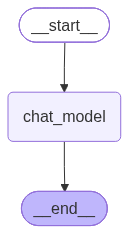

In [25]:
bot

In [37]:
response = bot.invoke({"messages": [HumanMessage(content="Hello, how are you?")]})

In [38]:
response["messages"][-1].text

"Hello! I'm doing well, thank you for asking. How are you doing today? How can I help you?"

In [39]:
response["messages"]

[HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='d5578ac9-854c-465c-9382-86ed2515a676'),
 AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How are you doing today? How can I help you?", 'extras': {'signature': 'Ep0HCpoHAWkUfRP7/c1U9g0r9GOCCNMRleGd+Z/4lNtTLxXyW9H8Oe4MWxPspBACXTuh+v01SlFtrEN2huHSmXdC7mTop8PkS/AeuSkDc9EvYEbatANAmfnVUADUW3zzpak3vHdnyCdv2V30c+URsF52MvdwSre8dmLEG2bzSMPj/6pdA7cZJX0LlPrGaSvj32OqIZdAQOcn7MbzoXIuVfbKQAwkyQ/MBzN3PohVUS2SYng1WtVC52hguJtQzl8J48dGlztnzukqc8pmUKMFEdDS69NUkwrdNq6G5okXIBy92Jnx/JUqADqlENimaRkUFxBFKcTBd9Mw0TzpLnViWuRoVfdArl6Q0Cpo96mInlJySQ8sTrGDWCi4UoxKI9NtUyPt0s9VL9dFB+bGMZU1FGvJfHMf6RcBcVsP6SgbYEY0/w/1lIrqOlGIfUNvs71xZaWOpm1t+J9Ll+JyegN1SEKZPlOsSmGNNsWsFE/VO8lJ34uKIpJN0ZAaPDEEe+xenA+thCivNssQdWZmB2Hbtt07JQJTzPzE26SE25l5z+HJIBNQlt4uMdfR62Lv83bU9AhfAVk8th4SGDr1GVWquhig2E3fRP4MACpPTS5c7G3Xi3F7kZof8APupzH8QWlcfXezbFRpH0ZatzeKrBSKdjFt+6lYlLvSIUVoLI1r4MeLRhIOrWKORQaDq5lKU43v

In [42]:
type(response["messages"][1])

list

In [46]:
type(response["messages"][1])

langchain_core.messages.ai.AIMessage

In [ ]:
[{"type": "text", "text": "Hello! ..."}]

AttributeError: 'list' object has no attribute 'text'